<a href="https://colab.research.google.com/github/ollihansen90/Mathe-SH/blob/main/Histogrammausgleich.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Was ist ein Histogramm?
Ein Histogramm ist ein Diagramm in welchem die Häufigkeit von Datenpunkten dargestellt wird.



## Wir schauen uns ein Beispiel an:
Der Datensatz betrachtet u.a. das Körpergewicht von verschiedenen Pinguinarten.

In [ ]:
import seaborn as sns
# Datensatz laden
daten = sns.load_dataset("penguins")
print(daten)
print(daten["species"].unique())

Die Verteilung der Gewichtsdaten aus diesem Datensatz stellen wir jetzt mit einem Histogramm dar!

In [ ]:
import matplotlib.pyplot as plt

# Histogramm des Körpergewichts erstellen
plt.hist(daten["body_mass_g"].dropna(),
         bins=15,
         edgecolor="black")

plt.title("Verteilung des Körpergewichts von Pinguinen")
plt.xlabel("Körpergewicht (g)")
plt.ylabel("Häufigkeit")
plt.show()

ABER: Wir haben gesehen, es gibt verschiedene Pinguinarten, macht das einen Unterschied?

In [ ]:
arten = daten["species"].unique()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, art in zip(axes, arten):
    artdaten = daten[daten["species"] == art]
    ax.hist(artdaten["body_mass_g"].dropna(),
            bins=15,
            edgecolor="black")
    ax.set_title(art)
    ax.set_xlabel("Körpergewicht (g)")
    ax.set_ylabel("Häufigkeit")
plt.suptitle("Körpergewichtsverteilung der Pinguinarten")
plt.show()

Wir sehen: Besonders die Gentoo-Pinguine sind schwerer als die Pinguine der anderen Arten!
Dies können wir im ersten Histogramm nicht sehen!

## Eigenschaften von Histogrammen

Histogramme haben folgende Vorteile:


*   Übersichtliche Darstellung großer Datenmengen.
*   Verteilung und Streuung der Daten visuell erkennbar
*   Aureißer sind schnell zu erkennnen
*   Vergleichbarkeit "ähnlicher" Datengruppen

und folgende Nachteile:


*   Nicht nach Einflussfaktoren differenziert
*   Informationen über die Reihenfolge der Daten gehen verloren. (zB. Zeitreihen)






# **Histogrammausgleich (Bildverarbeitung)**
## **Problemstellung: Keine Kontraste**

Ein digitales Bild kann fantastische Details enthalten, doch manchmal sehen wir sie einfach nicht. Das passiert vor allem dann, wenn die Tonwerte eines Bildes nicht gleichmäßig über den verfügbaren Helligkeitsbereich verteilt sind, sondern in einem sehr engen Spektrum verteilt sind.

Man unterscheidet hierbei meist zwei typische Problemfälle:

**Unterbelichtung (*Low-Key*):** Fast alle Pixelwerte drängeln sich im dunklen Bereich nahe Schwarz (geringe Helligkeitswerte). Feine Nuancen im Schatten gehen verloren.

**Überbelichtung (*High-Key*):** Die Werte ballen sich im extrem hellen Bereich nahe Weiß. Helle Texturen verwaschen.

In beiden Fällen sprechen wir von einem geringen Kontrast. Das menschliche Auge benötigt jedoch deutliche Helligkeitsunterschiede zwischen benachbarten Flächen, um Formen, Kanten und feine Strukturen voneinander abzugrenzen

### **Beispiel:**

Vor der Korrektur:  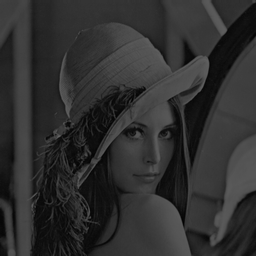

Nach der Korrektur: 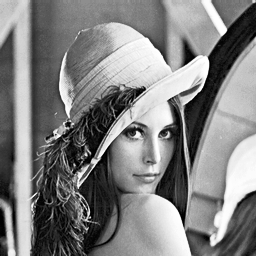

## Was sind Bilder? Ein kurzer Recap:

Ein Bild besteht aus **n * m** ***Pixeln***. In diesem Projekt ist ein Bild ein ***Grauwertbild*** (umgangssprachlich auch Schwarz-Weiß-Bild), das bedeutet: jeder Pixel hat einen **ganzzahligen Wert von 0 bis 255**. Dieser gibt an wie Hell dieser Pixel ist. Bei 0 ist der Pixel ganz aus, also Schwarz. Bei 255 ist der Pixel ganz an/hell also Weiß.

Ein Bild besteht aus Reihen und Zeilen auf die wir wie in verschachtelten Listen zugreifen können. Um über alle Pixel zu iterieren können wir verschachtelte *for-Schleifen* nutzen.

Ein Beispiel:

Wir erzeugen ein leeres Bild der größe 10x10 und machen den Pixel in der 5. Zeile und 5. Spalte "an".
```
bild = np.zeros(10,10)
bild[4,4] = 255
```
Ja 5, denn wie immer beginnen wir bei 0 zu zählen!

Wollen wir mehrere Pixel am Stück verändern, können wir auch auf mehrere Pixel aufeinmal bearbeiten
```
bild[3:6,3:6] = 255
```
Jetzt ist die ganze Mitte Weiß.

In [ ]:
# Wir importieren zunächst die notwendigen Bibliotheken für dieses Projekt
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import imageio
import requests

Das Bild wird eingelesen:

In [ ]:
url = "https://raw.githubusercontent.com/Bar0nVeng30us/Pythonkurs/main/peppers.png"
peppers = np.asarray(imageio.v2.imread(requests.get(url, stream=True).raw))
plt.imshow(peppers, cmap = 'gray')
plt.show()
#Transformieren das Bild um es künstlich zu stören
image = np.zeros(peppers.shape, dtype = np.uint8)
for x in range(peppers.shape[0]):
    for y in range(peppers.shape[1]):
        image[x][y] = (128 + ((int(peppers[x][y]) * 64) // 255))
plt.imshow(image, vmin = 0, vmax = 255, cmap = 'gray')
plt.show()

### Wie sind die Helligkeitswerte verteilt?

Dafür schreiben wir uns eine Funktion, welche die **absolute Anzahl** der Pixel mit den bestimmten Helligkeitswerten zurückgibt.

Tipp: Wir nutzen hierfür naiv verschachtelte Schleifen, um jeden Pixel im Bild abzufragen und die Helligkeit zu zählen.

In [ ]:
def farbverteilung(img):
    """
    Bestimmt die absolute Häufigkeit der Helligkeitswerte im Bild.

    Parameter:
    img (numpy.ndarray): Eingabebild von dem die Helligkeitswerte gezählt werden.

    Ausgabe:
    numpy.ndarray: Array (256,) mit der absoluten Häufigkeit der Helligkeitswerte.
    """
    # erstelle einen array mit 256 Einträgen, alle = 0
    helligkeit = np.zeros(256)

    n,m = img.shape # n,m sind die Breite bzw. Höhe des Bildes in Pixeln

    #bestimme jetzt die Farbverteilung
    for x in range(n):
        for y in range(m):
            # Tipp an welcher Stelle in 'helligkeit' soll was gespeichert werden?
            # Lösung:


    return helligkeit

Teste deine Lösung:

In [ ]:
farben = farbverteilung(image)
#Plotten dies im Barplot
fig, ax = plt.subplots()
ax.bar(range(256), farben)
ax.set_title("Histogramm der Farbdaten")
ax.set_xlabel("Helligkeit")
ax.set_ylabel("Pixelanzahl")
plt.show()

## *Histogramm* heißt das Zauberwort
Das ganze nennt sich Histogramm (wie oben eingeführt) und hat eine eigene Funktion:

In [ ]:
plt.hist(image.ravel(), bins = 256, range = (0, 255))
plt.title("Histogramm der Farbdaten")
plt.xlabel("Helligkeit")
plt.ylabel("Pixelanzahl")
plt.show()

Uns interessiert jetzt das kommulative Histogramm, also die Summe der Häufigkeiten der Helligkeitswerte bis zu jedem einzelnen Wert. Das lässt sich leicht implementieren:

In [ ]:
def my_kummsum(array):
    """
    Bestimmt bis zu jedem Wert die kummulative Häufigkeit der Helligkeitswerte im Bild.

    Parameter:
    img (numpy.ndarray): Eingabebild als 1D-Array von dem die Helligkeitswerte gezählt werden.

    Ausgabe:
    numpy.ndarray: Array (256,) mit der kummulativen Häufigkeit der Helligkeitswerte.
    """
    #lege den Lösungsarray an
    result = np.zeros(len(array), dtype=float)

    # ergänze hier deine Lösung


    return result

Probiere die Funktion aus:

In [ ]:
einsen = np.ones(100)
kumm_daten = my_kummsum(daten)
plt.plot(range(100), kumm_daten)
plt.show()

Versuche es jetzt nochmal mit `daten = np.array(range(100))`.

Auf unseren Bilddaten können wir diese Funktion jetzt auch anwenden:

In [ ]:
bild_daten = farbverteilung(image) #histogrammdaten des bildes
bild_kumm = my_kummsum(bild_daten)
plt.plot(range(256), bild_kumm)
plt.show()

Vergleiche dies mit der in der matplotlib-Bibliothek enthaltenen Histogramm Funktion, nutze `cumulative = True` als Argument.





In [ ]:
plt.hist(image.ravel(), bins = 256, cumulative = True, range = (0, 255))
plt.title("Kummulatives Histogramm der Farbdaten")
plt.xlabel("Helligkeit")
plt.ylabel("Pixelanzahl")
plt.show()

Wir können uns auch das Histogramm der Farbverteilung und das kummulative Histogramm der Farbdaten gemeinsam anschauen:

In [ ]:
fig, ax = plt.subplots()
ax.bar(range(256), farben, label = "Farbdaten", color = "Red")
ax_2 = ax.twinx()
ax_2.hist(image.ravel(), bins = 256, cumulative = True, range = (0, 255), histtype = "step", color="Blue", linewidth = 2)
plt.show()

Was fällt hier auf?

## Normalisierung
Um die Verteilung vergleichbar zu machen, normalisieren wir die Werte auf die Gesamtzahl der Pixel.
Dafür können wir die `my_kummsum`-Funktion nuten.


In [ ]:
num_pixels = image.size

# Normalisiere die Farbverteilung
normalisierte_farbverteilung =                      # Ergänze hier deine lösung

# Erstelle die Kummulative Farbverteilung
kummulative_kurve = my_kummsum(normalisierte_farbverteilung)

#Plote:
plt.plot(range(256), kummulative_kurve, label = "Kummulative Kurve")
plt.title("Normalisiertes Kurve der Helligekeitswerte")
plt.xlabel("Helligkeit")
plt.ylabel("Pixelanzahl")
plt.show()

## Der Ausgleich: Eine Abbildung

Das Ziel ist es, dass die Kurve der kummulierten Werte möglichst den ganzen Helligkeitsbereich abdeckt.

Dafür definieren wir folgende Abbildungsvorschrift:

> 0 -> 0

> 255 -> 255

und für alle anderen Werte:

> f(x) = 255 * F(x)

wobei F(x) die bereits bestimmte normalisierte kummulative Verteilung der Helligkeitswerte ist.


Vervollständige die Funktion des Histogrammausgleichs:

In [ ]:
def histogrammausgleich(img):
    """
    Führt einen Histogrammausgleich auf dem gegebenen Bild durch.

    Parameter:
    img (numpy.ndarray): Eingabebild (n,m), das angepasst werden soll.

    Ausgabe:
    numpy.ndarray: Bild (n,m) nach dem Histogrammausgleich.
    """
    # Berechne die absolute Häufigkeit der Helligkeitswerte
    farben =

    # Normalisiere die Häufigkeiten
    normalisierte_farbverteilung =

    # Berechne die kummulative Verteilung
    kummulative_kurve =

    # Erstelle eine Abbildungsvorschrift basierend auf der kummulativen Verteilung
    abbildungsvorschrift =

    # Wende die Abbildungsvorschrift auf das Bild an
    ausgeglichenes_bild =

    return ausgeglichenes_bild.astype(np.uint8) #Datenformat unseres Bildes

## Die Rekonstruktion

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 6))

# Originalbild anzeigen
ax[0].imshow(peppers, vmin = 0, vmax = 255, cmap = 'gray')
ax[0].set_title("Originalbild")

# gestörtes Bild anzeigen
ax[1].imshow(image, vmin = 0, vmax = 255, cmap = 'gray')
ax[1].set_title("Gestörtes Bild")

# Histogrammausgleich durchführen
ausgeglichenes_bild = histogrammausgleich(image)

# Ausgeglichenes Bild anzeigen
ax[2].imshow(ausgeglichenes_bild, vmin = 0, vmax = 255, cmap = 'gray')
ax[2].set_title("Bild nach Histogrammausgleich")
plt.show()

Das rekonstruierte Bild sieht nicht wie das Ursprungsbild aus. Woran könnte das liegen?

In [ ]:
print(f"Die Helligkeitswerte des Originalbildes reichen von {peppers.min()} bis {peppers.max()}.")
print(f"Die Helligkeitswerte des gestörten Bildes reichen von {image.min()} bis {image.max()}.")
print(f"Die Helligkeitswerte des ausgeglichenen Bildes reichen von {ausgeglichenes_bild.min()} bis {ausgeglichenes_bild.max()}.")

Probiere andere Störungen:

In [ ]:
image = np.zeros(peppers.shape, dtype = np.uint8)
for x in range(peppers.shape[0]):
    for y in range(peppers.shape[1]):
        image[x][y] = (((int(peppers[x][y]) * 32) // 255))
plt.imshow(image, vmin = 0, vmax = 255, cmap = 'gray')
plt.show()

## Abschließende Fragen
Wo liegen die Grenzen der Methode?

Welche Bilder bereiten Probleme?

Dafür gibt es eine Lokale Version des Histogrammausgleichs: "CLAHE"
Eine Idee soll folgende Implementierung geben:

In [ ]:
def CLAHE(img, k= 4, l = -1):
    if l == -1:
        l = k
    n,m = img.shape
    clahe_img = np.zeros_like(img)
    for i in range(k):
        for j in range(l):
            sub_img = img[int(i*n/(k)):(int(n*(i+1)/k)),int(j*m/(l)):(int(m*(j+1)/l))]    # erstelle bildausschnitt
            clahe_img[int(i*n/(k)):(int(n*(i+1)/k)),int(j*m/(l)):(int(m*(j+1)/l))]  = histogrammausgleich(sub_img)
    return clahe_img

In [ ]:
plt.imshow(CLAHE(image,4,6),cmap="gray")
plt.show()

### Was noch fehlt:
Durch abschneiden (clipping) bei zu vielen hohen/niedrigen Werten werden die Ausreißer kontrolliert.

Durch "Interpolation" werden die Bildausschnitte miteinander verbunden.